# MATH 616: Computational Linear Algebra
## Coding Lab — Krylov Subspace Methods: Arnoldi, GMRES, and the Road to Implicit Layers

This notebook is the coding companion to the *Krylov Subspace Methods* notes. We build the Arnoldi basis and GMRES from scratch, reproduce every worked example and every table in the notes, test the convergence theory against experiments, and finish with the fixed-point and implicit-differentiation machinery that the deep equilibrium (DEQ) lectures will assume. Everything is **matrix-free**: the solvers only ever call a function `matvec(v)` that returns $Av$.

### Learning goals
By the end of the lab you should be able to:

- explain why the monomial Krylov basis is useless and build the Arnoldi basis instead, checking the Arnoldi relation $AQ_k = Q_{k+1}\tilde H_k$ numerically;
- implement GMRES, reproduce the hand computations from the notes, and track the residual with Givens rotations at no extra cost;
- predict GMRES convergence from the spectrum (few eigenvalues, clustered eigenvalues) and recognize when eigenvalues lie (non-normal matrices);
- use SciPy's `gmres` with a `LinearOperator`, with restarts, and with a preconditioner, on a problem where the matrix is never formed;
- solve a nonlinear fixed-point problem by fixed-point iteration, Newton's method, and Anderson acceleration;
- differentiate through a fixed point with the implicit function theorem, check the result against finite differences and against unrolled backpropagation, and solve the backward linear system with the Neumann series and with GMRES.

Sections marked ✏️ are for you to edit and re-run. Random matrices use a fixed seed, so your numbers should match the executed copy.

## 0. Imports and helpers

In [ ]:
import numpy as np
import scipy.linalg as sla
import scipy.sparse as sp
import scipy.sparse.linalg as spla
import matplotlib.pyplot as plt

np.set_printoptions(precision=4, suppress=True, linewidth=120)
rng = np.random.default_rng(616)


class Counted:
    "Wrap a matrix (dense or sparse) or a function so that every product A @ v is counted."
    def __init__(self, A):
        self.A, self.count = A, 0
    def __call__(self, v):
        self.count += 1
        return self.A(v) if callable(self.A) else self.A @ v


def fmt_row(label, values, width=11):
    "One aligned table row of numbers in scientific notation."
    return f"{label:>14}" + "".join(f"{v:>{width}.1e}" if v is not None else " " * width for v in values)

# Part I. Krylov subspaces

## 1. The monomial basis is useless

The Krylov subspace $\mathcal K_k(A,b) = \operatorname{span}\{b, Ab, \dots, A^{k-1}b\}$ is a perfectly good subspace, but the vectors $A^jb$ are a terrible basis for it: the power method tells us they all line up with the dominant eigenvector. We measure this on the $100\times100$ one-dimensional Laplacian (the tridiagonal matrix with $2$ on the diagonal and $-1$ beside it) with $b = (1,\dots,1)^T$.

In [ ]:
def laplacian1d(n):
    return sp.diags([-1.0, 2.0, -1.0], [-1, 0, 1], shape=(n, n)).tocsr()


def krylov_matrix(matvec, b, k):
    "Columns b, Ab, ..., A^{k-1} b, each normalized to unit length."
    K = np.zeros((b.size, k))
    v = b.copy()
    for j in range(k):
        K[:, j] = v / np.linalg.norm(v)
        v = matvec(v)
    return K


n = 100
L = laplacian1d(n)
b = np.ones(n)
print(f"{'k':>3} {'cond(K_k)':>12} {'angle between last two columns (deg)':>40}")
for k in [3, 5, 8, 10, 15, 20]:
    K = krylov_matrix(lambda v: L @ v, b, k)
    ang = np.degrees(np.arccos(min(1.0, abs(K[:, -1] @ K[:, -2]))))
    print(f"{k:>3} {np.linalg.cond(K):>12.2e} {ang:>40.4f}")

  k    cond(K_k)     angle between last two columns (deg)
  3     4.33e+00                                  26.5651
  5     9.74e+01                                  10.4611
  8     1.42e+04                                   5.5133
 10     4.22e+05                                   4.1936
 15     2.26e+09                                   2.6243
 20     1.30e+13                                   1.9099


**Observe.** By $k = 20$ the condition number is $10^{13}$: in double precision the basis is numerically rank deficient, although the subspace itself is fine. The last two columns are less than a tenth of a degree apart. Any computation that expresses vectors in this basis (for instance, finding the best approximation to $A^{-1}b$ in $\mathcal K_k$) would lose essentially all its digits. The cure is to orthonormalize, which is what Arnoldi does.

## 2. The grade of a vector, and where the stationary iterates live

Two facts from the notes, checked numerically:

1. The Krylov subspaces stop growing at the *grade* $m$ of $b$, and $A^{-1}b \in \mathcal K_m$. For $A = \operatorname{diag}(1,1,2)$ and $b=(1,1,1)^T$ the notes find $m = 2$.
2. The Richardson iterates $x_{k+1} = x_k + \omega(b - Ax_k)$ from $x_0 = 0$ lie in $\mathcal K_k(A,b)$. We check this by projecting each iterate onto the Krylov subspace and measuring what is left over.

In [ ]:
A = np.diag([1.0, 1.0, 2.0]); b = np.ones(3)
for k in [1, 2, 3]:
    K = krylov_matrix(lambda v: A @ v, b, k)
    print(f"k = {k}: rank of [b, Ab, ..., A^(k-1) b] = {np.linalg.matrix_rank(K)}")
K2 = krylov_matrix(lambda v: A @ v, b, 2)
x = np.linalg.solve(A, b)
coef, *_ = np.linalg.lstsq(K2, x, rcond=None)
print("A^{-1} b =", x, "  distance from K_2:", np.linalg.norm(x - K2 @ coef))

# Richardson iterates of the 3x3 example from the notes lie in the Krylov subspaces
A3 = np.array([[2., -1, 0], [-1, 2, -1], [0, -1, 2]]); b3 = np.array([1., 0, 0])
x, omega = np.zeros(3), 0.5
for k in range(1, 4):
    x = x + omega * (b3 - A3 @ x)
    Kk = krylov_matrix(lambda v: A3 @ v, b3, k)
    coef, *_ = np.linalg.lstsq(Kk, x, rcond=None)
    print(f"Richardson x_{k} = {x},  distance from K_{k}: {np.linalg.norm(x - Kk @ coef):.1e}")

k = 1: rank of [b, Ab, ..., A^(k-1) b] = 1
k = 2: rank of [b, Ab, ..., A^(k-1) b] = 2
k = 3: rank of [b, Ab, ..., A^(k-1) b] = 2
A^{-1} b = [1.  1.  0.5]   distance from K_2: 1.3732700395566711e-15
Richardson x_1 = [0.5 0.  0. ],  distance from K_1: 0.0e+00
Richardson x_2 = [0.5  0.25 0.  ],  distance from K_2: 5.6e-17
Richardson x_3 = [0.625 0.25  0.125],  distance from K_3: 1.8e-16


# Part II. The Arnoldi iteration

## 3. Arnoldi and the Arnoldi relation

The function below is the one in the notes: modified Gram–Schmidt applied to $Aq_k$ at each step. It returns $Q$ with $k+1$ orthonormal columns and the $(k+1)\times k$ upper Hessenberg matrix $\tilde H_k$ with

$$AQ_k = Q_{k+1}\tilde H_k,\qquad Q_k^T A Q_k = H_k .$$

We check both identities, and reproduce the two worked examples from the notes (the symmetric tridiagonal matrix, where $H$ comes out tridiagonal, and the nonsymmetric one, where it does not).

In [ ]:
def arnoldi(matvec, b, k):
    "k steps of Arnoldi for K_k(A, b). Returns Q (n x (k+1)) and H ((k+1) x k); stops early on breakdown."
    n = b.size
    Q = np.zeros((n, k + 1))
    H = np.zeros((k + 1, k))
    Q[:, 0] = b / np.linalg.norm(b)
    for j in range(k):
        v = matvec(Q[:, j])
        for i in range(j + 1):                       # modified Gram-Schmidt
            H[i, j] = Q[:, i] @ v
            v = v - H[i, j] * Q[:, i]
        H[j + 1, j] = np.linalg.norm(v)
        if H[j + 1, j] < 1e-12 * np.linalg.norm(b):  # lucky breakdown
            return Q[:, :j + 1], H[:j + 1, :j + 1]
        Q[:, j + 1] = v / H[j + 1, j]
    return Q, H


def check_arnoldi(A, b, k, name):
    Q, H = arnoldi(lambda v: A @ v, b, k)
    kk = H.shape[1]
    print(f"--- {name}: {kk} steps" + ("  (breakdown: Krylov space is invariant)" if H.shape[0] == kk else ""))
    print("Q =\n", Q); print("H =\n", H)
    lhs, rhs = A @ Q[:, :kk], Q @ H
    print(f"||A Q_k - Q_(k+1) H~_k|| = {np.linalg.norm(lhs - rhs):.1e},   "
          f"||Q^T Q - I|| = {np.linalg.norm(Q.T @ Q - np.eye(Q.shape[1])):.1e}")


check_arnoldi(A3, b3, 3, "symmetric tridiagonal example")
A_ns = np.array([[2., 1, 0], [0, 3, 1], [1, 0, 4]])
check_arnoldi(A_ns, np.array([1., 0, 0]), 3, "nonsymmetric example")

--- symmetric tridiagonal example: 3 steps  (breakdown: Krylov space is invariant)
Q =
 [[ 1.  0.  0.]
 [ 0. -1.  0.]
 [ 0.  0.  1.]]
H =
 [[2. 1. 0.]
 [1. 2. 1.]
 [0. 1. 2.]]
||A Q_k - Q_(k+1) H~_k|| = 0.0e+00,   ||Q^T Q - I|| = 0.0e+00
--- nonsymmetric example: 3 steps  (breakdown: Krylov space is invariant)
Q =
 [[1. 0. 0.]
 [0. 0. 1.]
 [0. 1. 0.]]
H =
 [[2. 0. 1.]
 [1. 4. 0.]
 [0. 1. 3.]]
||A Q_k - Q_(k+1) H~_k|| = 0.0e+00,   ||Q^T Q - I|| = 0.0e+00


**Observe.** Both runs break down at step $3 = n$, as they must. In the symmetric case $H_3$ is tridiagonal (and equals $Q_3^T A Q_3$, a sign-flipped copy of $A$); in the nonsymmetric case the entry $h_{13} = 1$ sits above the superdiagonal. Compare the matrices with the hand computations in the notes: they agree entry for entry.

## 4. Ritz values: eigenvalue information for free

The eigenvalues of the small matrix $H_k = Q_k^T A Q_k$ are the *Ritz values*. On the $100\times100$ Laplacian, whose eigenvalues are $2 - 2\cos(j\pi/101)$, we plot the Ritz values after $k = 5, 10, 20, 40$ steps against the true spectrum.

k =  5: smallest Ritz value 0.128533  largest 3.840394
k = 10: smallest Ritz value 0.026261  largest 3.959002
k = 20: smallest Ritz value 0.006036  largest 3.982371
k = 40: smallest Ritz value 0.001878  largest 3.996034
k = 60: smallest Ritz value 0.001182  largest 3.996211
true:  smallest eigenvalue   0.000967  largest 3.999033


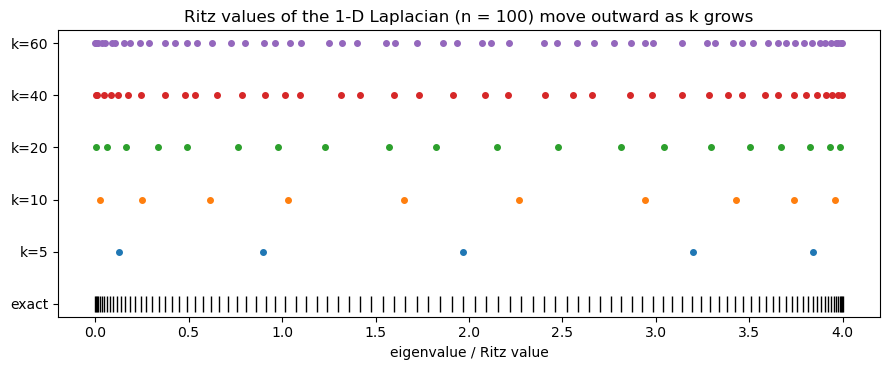

In [ ]:
n = 100
L = laplacian1d(n); Ld = L.toarray()
true_eigs = np.linalg.eigvalsh(Ld)
b = rng.standard_normal(n)

fig, ax = plt.subplots(figsize=(9, 3.8))
ks = [5, 10, 20, 40, 60]
for row, k in enumerate(ks):
    Q, H = arnoldi(lambda v: L @ v, b, k)
    ritz = np.sort(np.linalg.eigvals(H[:k, :k]).real)
    ax.plot(ritz, np.full(k, row + 1), "o", ms=4, label=f"k = {k}")
    print(f"k = {k:>2}: smallest Ritz value {ritz[0]:.6f}  largest {ritz[-1]:.6f}")
ax.plot(true_eigs, np.zeros(n), "|", color="k", ms=12, label="true eigenvalues")
print(f"true:  smallest eigenvalue   {true_eigs[0]:.6f}  largest {true_eigs[-1]:.6f}")
ax.set(yticks=range(len(ks) + 1), yticklabels=["exact"] + [f"k={k}" for k in ks],
       xlabel="eigenvalue / Ritz value", title="Ritz values of the 1-D Laplacian (n = 100) move outward as k grows")
plt.tight_layout(); plt.show()

**Observe.** The Ritz values approach the spectrum from the inside, the extreme ones first, and the interior ones fill in later. Convergence at the two ends is slowed down here by clustering: the Laplacian's eigenvalues near $0$ (and, symmetrically, near $4$) are spaced only $0.003$ apart, and Ritz values converge fast to *well separated* extreme eigenvalues and slowly to clustered ones. Even so, with $60$ products the largest Ritz value is within $0.003$ of $\lambda_{\max}$ and the smallest within $0.0003$ of $\lambda_{\min}$, for a $100\times100$ matrix that was never factored. This is the mechanism behind `scipy.sparse.linalg.eigs` (ARPACK), which restarts Arnoldi cleverly to keep the basis small.

### ✏️ Your turn: a nonsymmetric matrix
Ritz values of a nonsymmetric matrix are complex. Run the cell below for a random $200\times200$ matrix scaled by $1/\sqrt n$ (its eigenvalues fill a disk) and watch where the Ritz values land. Try `k = 10, 40, 100`, and try adding `5 * np.eye(n)` to shift the spectrum away from the origin.

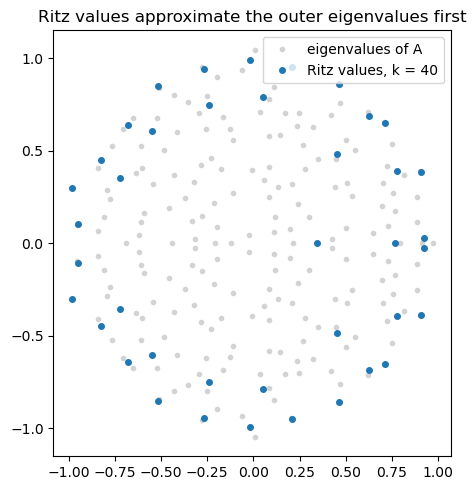

In [ ]:
n = 200
G = rng.standard_normal((n, n)) / np.sqrt(n)          # <-- try: G = G + 5 * np.eye(n)
k = 40                                                 # <-- try 10, 40, 100
Q, H = arnoldi(lambda v: G @ v, rng.standard_normal(n), k)
ritz = np.linalg.eigvals(H[:k, :k]); eigs = np.linalg.eigvals(G)
plt.figure(figsize=(5, 5))
plt.plot(eigs.real, eigs.imag, ".", color="lightgray", label="eigenvalues of A")
plt.plot(ritz.real, ritz.imag, "o", ms=4, label=f"Ritz values, k = {k}")
plt.gca().set_aspect("equal"); plt.legend(); plt.title("Ritz values approximate the outer eigenvalues first")
plt.tight_layout(); plt.show()

## 5. Three ways to orthonormalize the same subspace

Section 1 showed that the monomial basis $b, Ab, \dots, A^{k-1}b$ of $\mathcal K_k$ is ill-conditioned. One might hope to repair it afterwards by Gram–Schmidt. The cell compares three ways of producing an orthonormal basis of the *same* subspace:

- **classical Gram–Schmidt** applied to the columns of the monomial Krylov matrix $K_k$ (all inner products from the original column);
- **modified Gram–Schmidt** applied to the same columns (each inner product from the partially orthogonalized vector);
- **Arnoldi**, which never forms $A^jb$ at all but orthogonalizes $Aq_j$ against the orthonormal vectors already built.

The quantity reported is the loss of orthogonality $\|Q^TQ - I\|_2$.

In [ ]:
def gram_schmidt(K, modified):
    "Orthonormalize the columns of K by classical (modified=False) or modified Gram-Schmidt."
    Q = np.zeros_like(K)
    for j in range(K.shape[1]):
        v = K[:, j].copy()
        if modified:
            for i in range(j):
                v = v - (Q[:, i] @ v) * Q[:, i]
        else:
            v = v - Q[:, :j] @ (Q[:, :j].T @ K[:, j])
        Q[:, j] = v / np.linalg.norm(v)
    return Q


n = 100; L = laplacian1d(n); b = np.ones(n); mv = lambda v: L @ v
loss = lambda Q: np.linalg.norm(Q.T @ Q - np.eye(Q.shape[1]), 2)
print(f"{'k':>3} {'cond(K_k)':>10} {'classical GS on K_k':>20} {'modified GS on K_k':>19} {'Arnoldi':>10}")
for k in [5, 10, 15, 20, 30]:
    K = krylov_matrix(mv, b, k)
    Qa, _ = arnoldi(mv, b, k)
    print(f"{k:>3} {np.linalg.cond(K):>10.1e} {loss(gram_schmidt(K, False)):>20.1e} "
          f"{loss(gram_schmidt(K, True)):>19.1e} {loss(Qa[:, :k]):>10.1e}")

  k  cond(K_k)  classical GS on K_k  modified GS on K_k    Arnoldi
  5    9.7e+01              3.2e-13             1.1e-13    1.8e-14
 10    4.2e+05              1.2e-03             1.3e-10    7.3e-14
 15    2.3e+09              4.0e+00             1.3e-06    1.6e-13
 20    1.3e+13              5.7e+00             1.0e-02    3.1e-13
 30    7.1e+16              1.3e+01             1.0e+00    7.3e-13


**Observe.** Classical Gram–Schmidt on the monomial basis is useless already at $k = 10$ and produces a "basis" with nearly parallel columns by $k = 15$. Modified Gram–Schmidt is better by many orders of magnitude but still degrades like $\varepsilon_{\text{mach}}\,\kappa(K_k)$ and fails at $k = 30$. Arnoldi stays at round-off level throughout: it never touches the ill-conditioned vectors $A^jb$, because each new direction $Aq_j$ is computed from an already orthonormal vector. The lesson is that *how* you generate the Krylov vectors matters as much as how you orthogonalize them. Production codes use Arnoldi with modified Gram–Schmidt, or classical Gram–Schmidt applied twice ("twice is enough"), which is Exercise 2.

# Part III. GMRES

## 6. GMRES from the Arnoldi relation

GMRES picks $x_k \in \mathcal K_k$ with the smallest residual $\|b - Ax_k\|_2$. With $x_k = Q_k y$ the Arnoldi relation turns this into the $(k+1)\times k$ least squares problem

$$y_k = \arg\min_y \|\beta e_1 - \tilde H_k y\|_2,\qquad \beta = \|b\|_2,$$

whose minimum value *is* the residual norm. The first implementation solves this small problem with `lstsq` at every step, for clarity. The second updates a QR factorization of $\tilde H_k$ with one Givens rotation per step; then the residual norm is $|g_{k+1}|$ and no least squares solve is needed until the end. Both return the list of residual norms, so we can check that they agree.

In [ ]:
def gmres(matvec, b, tol=1e-8, maxit=50):
    "GMRES with x0 = 0, small least squares problem solved by lstsq each step. Returns x, residual norms."
    n = b.size
    beta = np.linalg.norm(b)
    Q = np.zeros((n, maxit + 1)); H = np.zeros((maxit + 1, maxit))
    Q[:, 0] = b / beta
    resids = [beta]
    for k in range(maxit):
        v = matvec(Q[:, k])
        for i in range(k + 1):
            H[i, k] = Q[:, i] @ v
            v = v - H[i, k] * Q[:, i]
        H[k + 1, k] = np.linalg.norm(v)
        if H[k + 1, k] > 1e-14 * beta:
            Q[:, k + 1] = v / H[k + 1, k]
        e1 = np.zeros(k + 2); e1[0] = beta
        y, *_ = np.linalg.lstsq(H[:k + 2, :k + 1], e1, rcond=None)
        resids.append(np.linalg.norm(e1 - H[:k + 2, :k + 1] @ y))
        if resids[-1] <= tol * beta or H[k + 1, k] <= 1e-14 * beta:
            break
    return Q[:, :k + 1] @ y, resids


def gmres_givens(matvec, b, tol=1e-8, maxit=50):
    "GMRES with the QR factorization of H~_k updated by Givens rotations; residual norm = |g_{k+1}| for free."
    n = b.size
    beta = np.linalg.norm(b)
    Q = np.zeros((n, maxit + 1)); R = np.zeros((maxit + 1, maxit))
    cs, sn = np.zeros(maxit), np.zeros(maxit)
    g = np.zeros(maxit + 1); g[0] = beta
    Q[:, 0] = b / beta
    resids = [beta]
    for k in range(maxit):
        v = matvec(Q[:, k])
        h = np.zeros(k + 2)
        for i in range(k + 1):
            h[i] = Q[:, i] @ v
            v = v - h[i] * Q[:, i]
        h[k + 1] = np.linalg.norm(v)
        if h[k + 1] > 1e-14 * beta:
            Q[:, k + 1] = v / h[k + 1]
        for i in range(k):                                   # apply the old rotations to the new column
            h[i], h[i + 1] = cs[i] * h[i] + sn[i] * h[i + 1], -sn[i] * h[i] + cs[i] * h[i + 1]
        r = np.hypot(h[k], h[k + 1])                         # the new rotation zeroes h[k+1]
        cs[k], sn[k] = h[k] / r, h[k + 1] / r
        h[k], h[k + 1] = r, 0.0
        g[k], g[k + 1] = cs[k] * g[k], -sn[k] * g[k]
        R[:k + 2, k] = h
        resids.append(abs(g[k + 1]))
        if resids[-1] <= tol * beta or h[k] <= 1e-14 * beta:
            break
    y = sla.solve_triangular(R[:k + 1, :k + 1], g[:k + 1])
    return Q[:, :k + 1] @ y, resids


# the worked example of the notes: residuals 1, 1/sqrt(5), 1/sqrt(14), 0
x_a, res_a = gmres(lambda v: A3 @ v, b3)
x_b, res_b = gmres_givens(lambda v: A3 @ v, b3)
print("lstsq version :", np.array(res_a), "  x =", x_a)
print("Givens version:", np.array(res_b), "  x =", x_b)
print("expected      :", np.array([1, 1 / np.sqrt(5), 1 / np.sqrt(14), 0]), "  x =", np.linalg.solve(A3, b3))

# the nonsymmetric example: residuals 1, 1/sqrt(5), 1/sqrt(69), 0
x_c, res_c = gmres_givens(lambda v: A_ns @ v, np.array([1., 0, 0]))
print("\nnonsymmetric  :", np.array(res_c), "  x =", x_c, "  expected 1/sqrt(69) =", 1 / np.sqrt(69))

lstsq version : [1.     0.4472 0.2673 0.    ]   x = [0.75 0.5  0.25]
Givens version: [1.     0.4472 0.2673 0.    ]   x = [0.75 0.5  0.25]
expected      : [1.     0.4472 0.2673 0.    ]   x = [0.75 0.5  0.25]

nonsymmetric  : [1.     0.4472 0.1204 0.    ]   x = [ 0.48  0.04 -0.12]   expected 1/sqrt(69) = 0.1203858530857692


## 7. GMRES against the stationary iterations

The notes prove that GMRES is never worse than Richardson's method (and therefore than Jacobi, which is Richardson on $D^{-1}A$) at the same number of products with $A$, because the Richardson iterate lies in the Krylov subspace over which GMRES minimizes. On the $3\times3$ example with $\omega = 1/2$ (which is Jacobi, since $D = 2I$), the notes' table is $0.447, 0.267, 0$ against $0.5, 0.354, 0.25$.

We confirm it there and on a larger problem: the 1-D Laplacian with $n = 100$, where Jacobi needs thousands of sweeps.

3x3 example   k : [1, 2, 3]
  GMRES         : [0.4472 0.2673 0.    ]
  Jacobi (w=1/2): [0.5    0.3536 0.25  ]


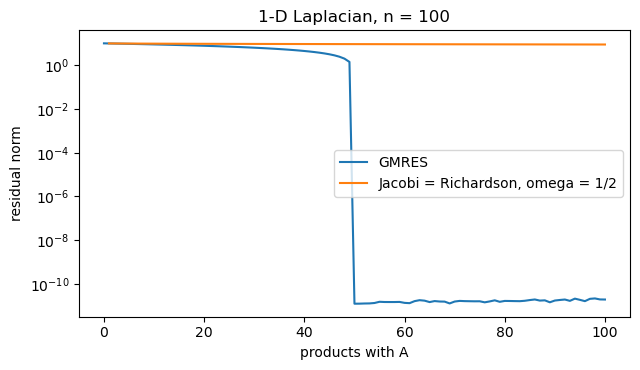

after 100 products: GMRES residual 1.9e-11, Jacobi residual 8.9e+00


In [ ]:
def richardson_residuals(matvec, b, omega, K):
    x, out = np.zeros_like(b), []
    for _ in range(K):
        x = x + omega * (b - matvec(x))
        out.append(np.linalg.norm(b - matvec(x)))
    return np.array(out)

print("3x3 example   k :", [1, 2, 3])
print("  GMRES         :", np.array(res_a[1:]))
print("  Jacobi (w=1/2):", richardson_residuals(lambda v: A3 @ v, b3, 0.5, 3))

n = 100; L = laplacian1d(n); b = np.ones(n)
K = 100
r_gm = np.array(gmres(lambda v: L @ v, b, tol=1e-14, maxit=K)[1])
r_ri = richardson_residuals(lambda v: L @ v, b, 0.5, K)   # Jacobi: D = 2I
plt.figure(figsize=(6.5, 3.8))
plt.semilogy(range(len(r_gm)), r_gm, label="GMRES")
plt.semilogy(range(1, K + 1), r_ri, label="Jacobi = Richardson, omega = 1/2")
plt.xlabel("products with A"); plt.ylabel("residual norm"); plt.title("1-D Laplacian, n = 100")
plt.legend(); plt.tight_layout(); plt.show()
print(f"after {K} products: GMRES residual {r_gm[-1]:.1e}, Jacobi residual {r_ri[-1]:.1e}")

**Observe.** GMRES is exact after $n = 100$ products (finite termination: the grade of $b$ is at most $n$) and is ahead of Jacobi at every single step, while Jacobi has barely moved: its reduction factor is $\cos(\pi/101) \approx 0.9995$. The gap is the whole point of Krylov methods. (Full GMRES stores all $100$ basis vectors here; Section 9 is about what happens when that is too much.)

## 8. Convergence and the spectrum

The convergence theorem says, for diagonalizable $A = V\Lambda V^{-1}$,

$$\frac{\|r_k\|_2}{\|b\|_2} \le \kappa_2(V)\ \min_{\deg p\le k,\ p(0)=1}\ \max_i |p(\lambda_i)| .$$

Three experiments from the notes test its consequences.

- **(a) Few distinct eigenvalues.** A dense $50\times50$ symmetric matrix with eigenvalues in $\{1,2,3\}$: GMRES must finish in three steps.
- **(b) Clustered versus spread.** Symmetric $100\times100$ matrices with eigenvalues equally spaced in $[1,3]$ and in $[0.2, 3.8]$. The disk bound predicts the factor $\rho/c = 0.5$ and $0.9$ per step; the Chebyshev bound $2\big(\tfrac{\sqrt\kappa-1}{\sqrt\kappa+1}\big)^k$ is sharper on an interval.
- **(c) Eigenvalues can lie.** $A = I - 2S$, with $S$ the $20\times20$ superdiagonal shift, has all eigenvalues equal to $1$ but is a single Jordan block. Watch the residual.

(a) three distinct eigenvalues, residual norms: [6.6123 2.0758 0.779  0.    ]


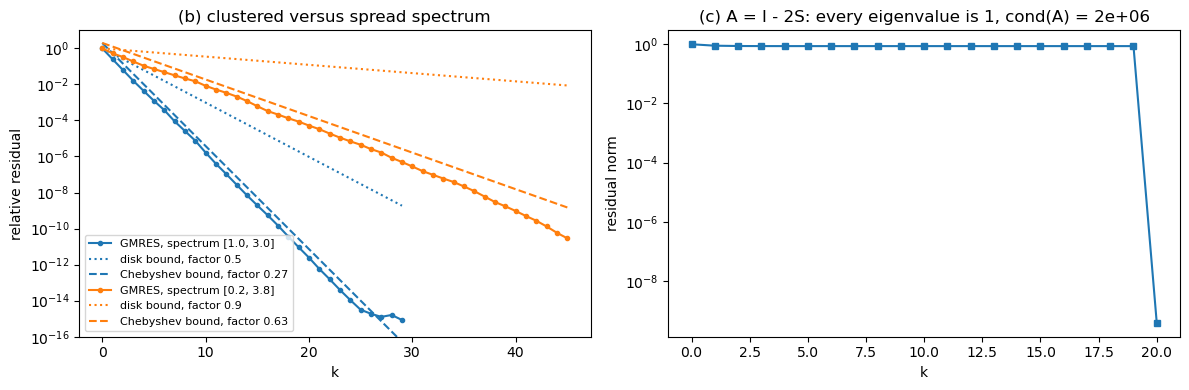

(c) residual norms at k = 1, 5, 10, 19, 20: [0.8944 0.8661 0.866  0.866  0.    ]


In [ ]:
def sym_with_spectrum(lam):
    V, _ = np.linalg.qr(rng.standard_normal((lam.size, lam.size)))
    return V @ np.diag(lam) @ V.T

# (a)
lam_a = np.array([1., 2., 3.])[rng.integers(0, 3, 50)]
A_a = sym_with_spectrum(lam_a); b_a = rng.standard_normal(50)
print("(a) three distinct eigenvalues, residual norms:", np.array(gmres(lambda v: A_a @ v, b_a, tol=1e-14)[1]))

# (b)
n = 100; b_b = rng.standard_normal(n); b_b /= np.linalg.norm(b_b)
fig, ax = plt.subplots(1, 2, figsize=(12, 4))
for (lo, hi), color in [((1.0, 3.0), "C0"), ((0.2, 3.8), "C1")]:
    A_b = sym_with_spectrum(np.linspace(lo, hi, n))
    res = np.array(gmres(lambda v: A_b @ v, b_b, tol=1e-15, maxit=45)[1])
    k = np.arange(len(res))
    c, rho, kappa = (lo + hi) / 2, (hi - lo) / 2, hi / lo
    ax[0].semilogy(k, res, "o-", ms=3, color=color, label=f"GMRES, spectrum [{lo}, {hi}]")
    ax[0].semilogy(k, (rho / c) ** k, ":", color=color, label=f"disk bound, factor {rho / c:.1f}")
    ax[0].semilogy(k, 2 * ((np.sqrt(kappa) - 1) / (np.sqrt(kappa) + 1)) ** k, "--", color=color,
                   label=f"Chebyshev bound, factor {(np.sqrt(kappa) - 1) / (np.sqrt(kappa) + 1):.2f}")
ax[0].set(ylim=(1e-16, 10), xlabel="k", ylabel="relative residual", title="(b) clustered versus spread spectrum")
ax[0].legend(fontsize=8)

# (c)
n = 20; S = np.eye(n, k=1); A_c = np.eye(n) - 2 * S; b_c = np.zeros(n); b_c[-1] = 1
res_c = np.array(gmres(lambda v: A_c @ v, b_c, tol=1e-15, maxit=25)[1])
ax[1].semilogy(res_c, "s-", ms=4)
ax[1].set(xlabel="k", ylabel="residual norm", title="(c) A = I - 2S: every eigenvalue is 1, cond(A) = %.0e" % np.linalg.cond(A_c))
plt.tight_layout(); plt.show()
print("(c) residual norms at k = 1, 5, 10, 19, 20:", res_c[[1, 5, 10, 19, 20]])

**Observe.**

- (a) Three steps, then a residual at round-off level, for a dense $50\times50$ matrix: GMRES only sees the three distinct eigenvalues.
- (b) Both curves beat the disk bound by a wide margin and track the Chebyshev bound, with factor about $0.27$ for $[1,3]$ and $0.63$ for $[0.2,3.8]$. On an interval, the best polynomial with $p(0)=1$ is a shifted Chebyshev polynomial, and that is also the conjugate gradient rate.
- (c) Nineteen steps of complete stagnation, then the exact answer at step $20$. The matrix is not diagonalizable, so the theorem does not apply, and its eigenvalues say nothing about GMRES. For non-normal matrices one needs pseudospectra or the field of values, not eigenvalues.

### ✏️ Your turn: non-normality by degrees
Replace `2 * S` in (c) by `t * S` for `t = 0.5, 1, 2, 4` and plot the four residual curves together. The eigenvalues never change. What does?

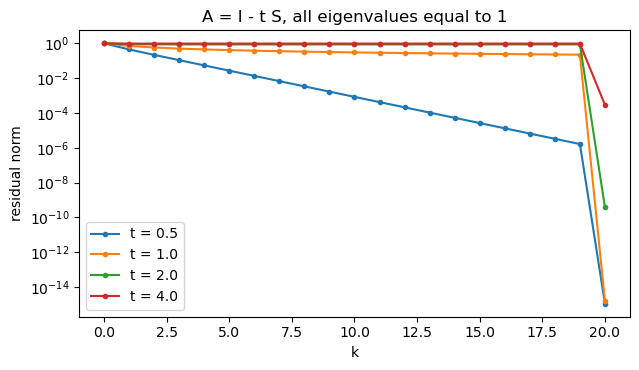

In [ ]:
n = 20; S = np.eye(n, k=1); b_c = np.zeros(n); b_c[-1] = 1
plt.figure(figsize=(6.5, 3.8))
for t in [0.5, 1.0, 2.0, 4.0]:                        # <-- edit
    A_t = np.eye(n) - t * S
    plt.semilogy(gmres(lambda v: A_t @ v, b_c, tol=1e-15, maxit=25)[1], "o-", ms=3, label=f"t = {t}")
plt.xlabel("k"); plt.ylabel("residual norm"); plt.legend(); plt.title("A = I - t S, all eigenvalues equal to 1")
plt.tight_layout(); plt.show()

## 9. Restarts

Step $k$ of GMRES stores $k+1$ vectors and does $O(kn)$ work in the orthogonalization. GMRES$(m)$ runs $m$ steps, forms $x_m$, and restarts from the new residual. The wrapper below reuses our `gmres` as the inner solver. We compare $m = 5, 10, 20$ with full GMRES on the spread spectrum $[0.2, 3.8]$ from Section 8, counting products with $A$.

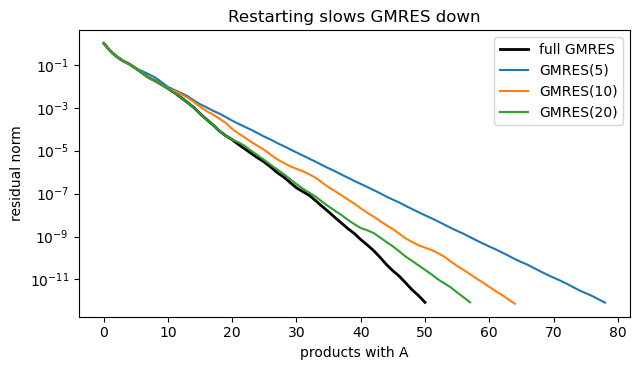

In [ ]:
def gmres_restarted(matvec, b, m, tol=1e-10, max_products=200):
    "GMRES(m): restart every m steps. Returns x and the residual norm after every product with A."
    x = np.zeros_like(b); nb = np.linalg.norm(b); hist = [nb]
    while len(hist) - 1 < max_products:
        r = b - matvec(x)
        dx, res = gmres(matvec, r, tol=tol * nb / np.linalg.norm(r), maxit=m)
        x = x + dx
        hist += res[1:]
        if hist[-1] <= tol * nb:
            break
    return x, np.array(hist)


n = 100
A_s = sym_with_spectrum(np.linspace(0.2, 3.8, n)); b_s = rng.standard_normal(n); b_s /= np.linalg.norm(b_s)
plt.figure(figsize=(6.5, 3.8))
plt.semilogy(gmres(lambda v: A_s @ v, b_s, tol=1e-12, maxit=80)[1], "k-", lw=2, label="full GMRES")
for m in [5, 10, 20]:
    _, h = gmres_restarted(lambda v: A_s @ v, b_s, m, tol=1e-12, max_products=80)
    plt.semilogy(h, "-", label=f"GMRES({m})")
plt.xlabel("products with A"); plt.ylabel("residual norm"); plt.legend(); plt.title("Restarting slows GMRES down")
plt.tight_layout(); plt.show()

**Observe.** All curves coincide for the first $m$ steps, then the restarted ones fall behind, more so for smaller $m$, because after each restart the method optimizes over a fresh, small subspace and has forgotten the directions it already explored. Here they still converge, since the spectrum stays away from $0$. On harder problems GMRES$(m)$ with small $m$ can stall at a constant residual forever; a good preconditioner is then the cure, not a larger $m$.

## 10. SciPy, a matrix that is never formed, and a preconditioner

Everything so far used a function `matvec`. SciPy's `gmres` accepts the same thing wrapped as a `LinearOperator`. We solve the 2-D Poisson problem from the iterative methods lab, $-\Delta u = 1$ on an $N\times N$ grid (a membrane under uniform load), applying the 5-point stencil directly to the grid array so that **no matrix is ever built**. The `Counted` wrapper counts the stencil applications, and the sparse direct solver provides a reference solution to measure the error against.

Then we add a preconditioner. An incomplete LU factorization (`spilu`) of the sparse matrix gives a cheap approximate inverse $P^{-1}$; GMRES on $P^{-1}Ax = P^{-1}b$ converges in far fewer steps because the spectrum of $P^{-1}A$ is clustered near $1$. (For this experiment we do form the sparse matrix, since `spilu` needs it.)

In [ ]:
def poisson_matvec(N):
    "Returns a function u -> A u for the 5-point Laplacian on an N x N grid, acting on flattened vectors."
    def mv(u):
        U = np.zeros((N + 2, N + 2)); U[1:-1, 1:-1] = u.reshape(N, N)
        return (4 * U[1:-1, 1:-1] - U[:-2, 1:-1] - U[2:, 1:-1] - U[1:-1, :-2] - U[1:-1, 2:]).ravel()
    return mv


def poisson2d(N):
    T = sp.diags([-1.0, 2.0, -1.0], [-1, 0, 1], shape=(N, N)); I = sp.identity(N)
    return (sp.kron(I, T) + sp.kron(T, I)).tocsc()


N = 64; n = N * N; h = 1 / (N + 1)
b = np.full(n, h**2)                                 # right-hand side f = 1
A_sp = poisson2d(N)
u_ref = spla.spsolve(A_sp, b)                        # sparse direct solution, for checking only

rows = []
for label, restart, M in [("GMRES(20), no preconditioner", 20, None),
                          ("GMRES(50), no preconditioner", 50, None),
                          ("full GMRES (restart = n)", n, None)]:
    mv = Counted(poisson_matvec(N))
    A_op = spla.LinearOperator((n, n), matvec=mv, dtype=float)
    its = []
    u, info = spla.gmres(A_op, b, rtol=1e-8, restart=restart, maxiter=2000, M=M,
                         callback=lambda r: its.append(r), callback_type="pr_norm")
    rows.append((label, mv.count, len(its), np.abs(u - u_ref).max()))

for drop in [1e-1, 1e-2, 1e-3]:
    ilu = spla.spilu(A_sp, drop_tol=drop, fill_factor=20)
    M = spla.LinearOperator((n, n), matvec=ilu.solve, dtype=float)
    mv = Counted(poisson_matvec(N)); A_op = spla.LinearOperator((n, n), matvec=mv, dtype=float)
    its = []
    u, info = spla.gmres(A_op, b, rtol=1e-8, restart=20, maxiter=2000, M=M,
                         callback=lambda r: its.append(r), callback_type="pr_norm")
    rows.append((f"GMRES(20) + ILU(drop {drop:g}), fill {(ilu.L.nnz + ilu.U.nnz) / A_sp.nnz:.1f}x",
                 mv.count, len(its), np.abs(u - u_ref).max()))

print(f"N = {N}, n = {n} unknowns, tolerance 1e-8 on the (preconditioned) residual\n")
print(f"{'method':>50} {'products with A':>16} {'iterations':>11} {'max error vs spsolve':>22}")
for label, cnt, its, err in rows:
    print(f"{label:>50} {cnt:>16d} {its:>11d} {err:>22.1e}")

N = 64, n = 4096 unknowns, tolerance 1e-8 on the (preconditioned) residual

                                            method  products with A  iterations   max error vs spsolve
                      GMRES(20), no preconditioner              915         871                9.6e-10
                      GMRES(50), no preconditioner              275         269                6.3e-10
                          full GMRES (restart = n)              119         118                2.2e-11
              GMRES(20) + ILU(drop 0.1), fill 2.2x               88          83                1.6e-10
             GMRES(20) + ILU(drop 0.01), fill 4.4x               21          19                3.2e-11
            GMRES(20) + ILU(drop 0.001), fill 7.3x               10           8                7.4e-13


**Observe.** Without a preconditioner, GMRES$(20)$ needs about $900$ stencil applications, GMRES$(50)$ about $300$, and full GMRES about $120$ (compare: Jacobi needed several thousand sweeps at this size in the previous lab). With an incomplete LU preconditioner the count drops to a few dozen or fewer, at the price of one approximate triangular solve per step and a few times the memory of $A$ for the factors. The error against the direct solution is at the level of the tolerance in every row.

### ✏️ Your turn
1. Change `N` to `128` (so $n = 16384$) and watch how the unpreconditioned counts grow while the preconditioned ones barely move. Then try `drop_tol = 1e-4`: more fill, fewer iterations. Where is the sweet spot in total time? (Wrap the calls in `%time`.)
2. Replace the right-hand side by `b = (h**2 * 2 * np.pi**2 * np.sin(np.pi * X) * np.sin(np.pi * Y)).ravel()` with `X, Y = np.meshgrid(xg, xg, indexing="ij")`, `xg = np.linspace(h, 1 - h, N)`. GMRES now converges in **one** step, with any restart and no preconditioner. Explain why, using the grade of $b$. (Hint: what is $\sin(\pi x)\sin(\pi y)$ for the discrete Laplacian?)

# Part IV. From linear solves to fixed points: what the DEQ lectures assume

## 11. A fixed-point layer and three ways to solve it

A deep equilibrium layer returns the fixed point $z^\star = f(z^\star)$ of a map such as $f(z) = \tanh(Wz + c)$. We use the $2\times2$ example of the notes and solve it by

- **fixed-point iteration** $z \leftarrow f(z)$, linear convergence with factor $\rho(J)$, $J = \partial f/\partial z = \operatorname{diag}(1 - z_i^2)\,W$;
- **Newton's method** $z \leftarrow z - (I - J)^{-1}(z - f(z))$, quadratic convergence, one linear solve per step;
- **Anderson acceleration**, which combines the last $m+1$ iterates with weights chosen by a small least squares problem, the same idea as GMRES. For a linear $f$ it *is* GMRES.

z* = [ 0.6875 -0.726 ]    rho(J) = 0.2546    ||J||_2 = 0.3083
Newton   z = [ 0.6875 -0.726 ]   Anderson z = [ 0.6875 -0.726 ]


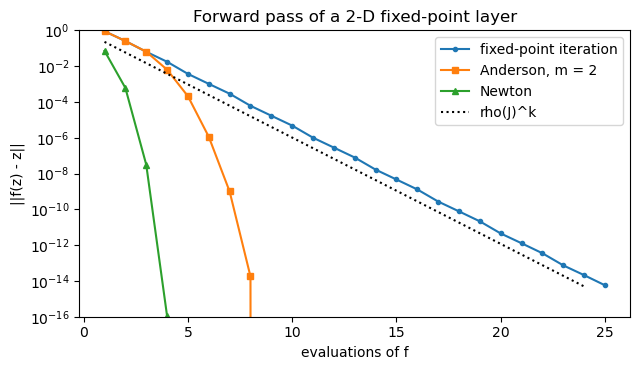

In [ ]:
W = np.array([[0.3, 0.5], [-0.4, 0.2]]); c = np.array([1.0, -0.5])
f = lambda z: np.tanh(W @ z + c)
jac = lambda z: np.diag(1 - f(z)**2) @ W            # Jacobian of f at z (evaluated through f(z))


def fixed_point(f, z0, tol=1e-14, maxit=200):
    z, hist = z0, []
    for _ in range(maxit):
        fz = f(z); hist.append(np.linalg.norm(fz - z)); z = fz
        if hist[-1] < tol: break
    return z, np.array(hist)


def newton(f, jac, z0, tol=1e-14, maxit=50):
    z, hist = z0, []
    for _ in range(maxit):
        z = z - np.linalg.solve(np.eye(z.size) - jac(z), z - f(z))
        hist.append(np.linalg.norm(f(z) - z))
        if hist[-1] < tol: break
    return z, np.array(hist)


def anderson(f, z0, m=5, tol=1e-14, maxit=100):
    "Anderson acceleration for z = f(z); returns z and residual norms after each evaluation of f."
    zs, fs = [z0], [f(z0)]
    hist = [np.linalg.norm(fs[0] - zs[0])]
    for k in range(maxit):
        mk = min(m, k)
        if mk == 0:
            z_new = fs[-1]
        else:
            R = np.array([fs[j] - zs[j] for j in range(-mk - 1, 0)]).T   # last mk+1 residuals
            F = np.array(fs[-mk - 1:]).T
            dR, dF = R[:, 1:] - R[:, :-1], F[:, 1:] - F[:, :-1]
            gamma, *_ = np.linalg.lstsq(dR, R[:, -1], rcond=None)
            z_new = fs[-1] - dF @ gamma
        zs.append(z_new); fs.append(f(z_new))
        hist.append(np.linalg.norm(fs[-1] - zs[-1]))
        if hist[-1] < tol: break
    return zs[-1], np.array(hist)


z0 = np.zeros(2)
z_fp, h_fp = fixed_point(f, z0)
z_nt, h_nt = newton(f, jac, z0)
z_aa, h_aa = anderson(f, z0, m=2)
z_star = z_fp
J = jac(z_star)
print("z* =", z_star, "   rho(J) =", max(abs(np.linalg.eigvals(J))).round(4), "   ||J||_2 =", np.linalg.norm(J, 2).round(4))
print("Newton   z =", z_nt, "  Anderson z =", z_aa)

plt.figure(figsize=(6.5, 3.8))
plt.semilogy(range(1, len(h_fp) + 1), h_fp, "o-", ms=3, label="fixed-point iteration")
plt.semilogy(range(1, len(h_aa) + 1), h_aa, "s-", ms=4, label="Anderson, m = 2")
plt.semilogy(range(1, len(h_nt) + 1), h_nt, "^-", ms=5, label="Newton")
plt.semilogy(range(1, 25), max(abs(np.linalg.eigvals(J))) ** np.arange(1, 25) * h_fp[0], "k:", label="rho(J)^k")
plt.ylim(1e-16, 1); plt.xlabel("evaluations of f"); plt.ylabel("||f(z) - z||"); plt.legend()
plt.title("Forward pass of a 2-D fixed-point layer"); plt.tight_layout(); plt.show()

**Observe.** Fixed-point iteration follows the line $\rho(J)^k$ exactly. Newton doubles the digits each step but needs a Jacobian and a solve. Anderson with memory $2$ reaches round-off in about eight evaluations using nothing but a $2\times2$ least squares problem per step, which is why it is the default forward solver in DEQ code.

### ✏️ Your turn: when the layer is not a contraction
Multiply `W` by `4` in the cell below. Fixed-point iteration no longer settles; does Anderson? Does Newton, from `z0 = np.zeros(2)` and from `z0 = np.array([0.5, 0.5])`? Print $\rho(J)$ at whatever Newton returns. This is the failure mode that spectral normalization and monotone DEQs are designed to rule out.

In [ ]:
scale = 4.0                                            # <-- try 1, 2, 4
W4 = scale * W
f4 = lambda z: np.tanh(W4 @ z + c)
jac4 = lambda z: np.diag(1 - f4(z)**2) @ W4
for name, solver in [("fixed-point", lambda z0: fixed_point(f4, z0, maxit=60)),
                     ("Anderson m=2", lambda z0: anderson(f4, z0, m=2, maxit=60)),
                     ("Newton", lambda z0: newton(f4, jac4, z0, maxit=30))]:
    for z0 in [np.zeros(2), np.array([0.5, 0.5])]:
        try:
            z, h = solver(z0)
            print(f"{name:>13} from {z0}: final residual {h[-1]:.1e}, z = {z}, rho(J(z)) = {max(abs(np.linalg.eigvals(jac4(z)))):.2f}")
        except np.linalg.LinAlgError as e:
            print(f"{name:>13} from {z0}: failed ({e})")

  fixed-point from [0. 0.]: final residual 8.0e-01, z = [-0.7025 -0.8935], rho(J(z)) = 0.77
  fixed-point from [0.5 0.5]: final residual 7.1e-01, z = [-0.8097 -0.7922], rho(J(z)) = 0.81
 Anderson m=2 from [0. 0.]: final residual 1.5e-16, z = [-0.2258 -0.4794], rho(J(z)) = 1.74


 Anderson m=2 from [0.5 0.5]: final residual 2.8e-17, z = [-0.2258 -0.4794], rho(J(z)) = 1.74
       Newton from [0. 0.]: final residual 0.0e+00, z = [-0.2258 -0.4794], rho(J(z)) = 1.74
       Newton from [0.5 0.5]: final residual 6.8e+00, z = [ 7.8256 -1.1266], rho(J(z)) = 0.00


## 12. Implicit differentiation, checked three ways

For a loss $\ell(z^\star)$ with $v = \nabla_z \ell$, the notes derive

$$\nabla_\theta \ell = \Big(\frac{\partial f}{\partial \theta}\Big)^{T} g,\qquad (I - J^T)\,g = v .$$

For $f(z) = \tanh(Wz + c)$ and $\ell = \tfrac12\|z^\star\|^2$ this gives $\nabla_W \ell = (Dg)\,z^{\star T}$ with $D = \operatorname{diag}(1 - z_i^{\star 2})$. We compare it with

1. a central finite difference of the loss, where each evaluation runs the forward solver to convergence;
2. **unrolled backpropagation** through $K$ fixed-point iterations, treated as $K$ layers. Its gradient should converge to the implicit one as $K$ grows, at the rate $\rho(J)$.

implicit gradient dl/dW =
 [[ 0.3392 -0.3582]
 [-0.1721  0.1818]]
finite differences      =
 [[ 0.3392 -0.3582]
 [-0.1721  0.1818]] 
max difference: 2.8257896023120566e-11


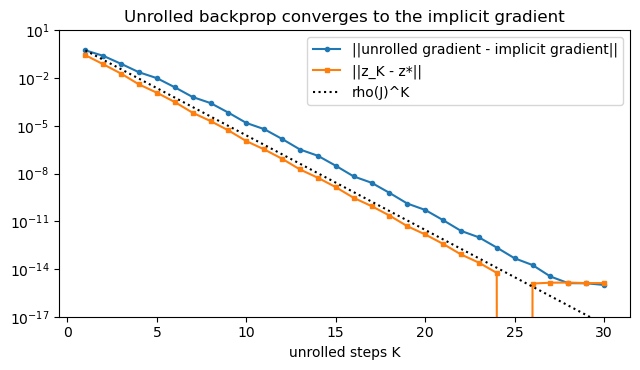

In [ ]:
D = 1 - z_star**2
g = np.linalg.solve(np.eye(2) - W.T @ np.diag(D), z_star)       # (I - J^T) g = v,  v = z*
grad_implicit = np.outer(D * g, z_star)
print("implicit gradient dl/dW =\n", grad_implicit)

def loss(Wm, iters=500):
    z = np.zeros(2)
    for _ in range(iters): z = np.tanh(Wm @ z + c)
    return 0.5 * z @ z

fd = np.zeros((2, 2)); hstep = 1e-6
for i in range(2):
    for j in range(2):
        E = np.zeros((2, 2)); E[i, j] = hstep
        fd[i, j] = (loss(W + E) - loss(W - E)) / (2 * hstep)
print("finite differences      =\n", fd, "\nmax difference:", np.abs(fd - grad_implicit).max())

def unrolled_grad(K):
    "Backpropagate the loss 0.5||z_K||^2 through K fixed-point iterations from z_0 = 0."
    zs = [np.zeros(2)]
    for _ in range(K): zs.append(np.tanh(W @ zs[-1] + c))
    a, G = zs[-1].copy(), np.zeros((2, 2))                     # adjoint of z_K, accumulated gradient
    for j in range(K - 1, -1, -1):
        Dj = 1 - zs[j + 1]**2
        G += np.outer(Dj * a, zs[j]); a = W.T @ (Dj * a)
    return G, zs[-1]

Ks = np.arange(1, 31)
errs = np.array([np.linalg.norm(unrolled_grad(K)[0] - grad_implicit) for K in Ks])
zerr = np.array([np.linalg.norm(unrolled_grad(K)[1] - z_star) for K in Ks])
rho = max(abs(np.linalg.eigvals(J)))
plt.figure(figsize=(6.5, 3.8))
plt.semilogy(Ks, errs, "o-", ms=3, label="||unrolled gradient - implicit gradient||")
plt.semilogy(Ks, zerr, "s-", ms=3, label="||z_K - z*||")
plt.semilogy(Ks, errs[0] * rho ** (Ks - 1), "k:", label="rho(J)^K")
plt.ylim(1e-17, 10); plt.xlabel("unrolled steps K"); plt.legend(); plt.title("Unrolled backprop converges to the implicit gradient")
plt.tight_layout(); plt.show()

**Observe.** The implicit gradient matches finite differences to about $10^{-9}$ (the finite-difference noise floor). The unrolled gradient converges to it at the rate $\rho(J)$, the same rate as the iterates, but it must store all $K$ intermediate vectors, and for small $K$ it is the gradient of a different function (the truncated network). Implicit differentiation costs one linear solve and $O(n)$ memory, independent of how the fixed point was found.

## 13. The backward solve: Neumann series versus GMRES, matrix-free

In a real DEQ the dimension $n$ is the width of the layer and $J$ is never formed; an autodiff library provides only the vector–Jacobian product $u \mapsto J^T u$. The backward system $(I - J^T)g = v$ is then exactly the matrix-free problem of Part I. Two solvers that need only this product:

- the **Neumann series** $g_k = \sum_{j<k}(J^T)^j v$, which is Richardson's method with $\omega = 1$ (and is what backpropagating through the unrolled iteration computes). Converges iff $\rho(J) < 1$, factor $\rho(J)$;
- **GMRES**, never worse at the same number of products, by the theorem in the notes.

We repeat the notes' $n = 200$ experiment (with a different random matrix), $J$ scaled to $\rho(J) = 0.9$, then run the same solve through SciPy's `gmres` with a `LinearOperator` that calls only `vjp`.

rho(J) = 0.900,   ||J||_2 = 1.722  (not a contraction in the 2-norm)

 products with J^T  Neumann residual  GMRES residual
                 1           8.6e-01         6.6e-01
                 2           7.4e-01         5.1e-01
                 5           4.5e-01         2.6e-01
                10           2.1e-01         9.4e-02
                20           4.4e-02         1.6e-02
                30           1.1e-02         2.7e-03
                40           3.3e-03         3.5e-04


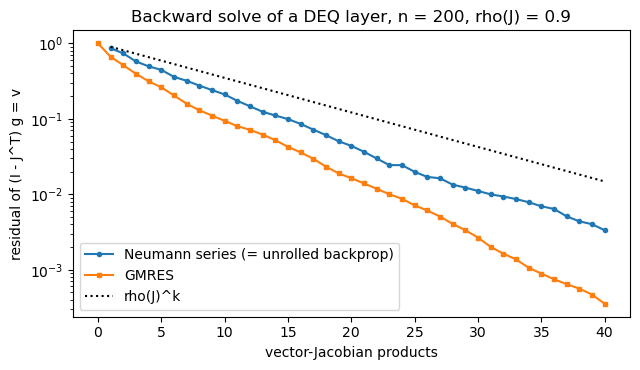


SciPy gmres: exit flag 0, 117 vector-Jacobian products, residual 9.6e-11

In [ ]:
n = 200
J_big = rng.standard_normal((n, n)) / np.sqrt(n)
J_big *= 0.9 / max(abs(np.linalg.eigvals(J_big)))
print(f"rho(J) = {max(abs(np.linalg.eigvals(J_big))):.3f},   ||J||_2 = {np.linalg.norm(J_big, 2):.3f}  (not a contraction in the 2-norm)")
v = rng.standard_normal(n); v /= np.linalg.norm(v)
vjp = lambda u: J_big.T @ u                               # the only access to J that autodiff would give us
M_apply = lambda u: u - vjp(u)                            # (I - J^T) u

# Neumann series: one vjp per term
g, neu = np.zeros(n), []
for k in range(40):
    g = v + vjp(g); neu.append(np.linalg.norm(v - M_apply(g)))
# GMRES: one vjp per step
_, gm = gmres(M_apply, v, tol=1e-15, maxit=40)

print(f"\n{'products with J^T':>18} {'Neumann residual':>17} {'GMRES residual':>15}")
for k in [1, 2, 5, 10, 20, 30, 40]:
    print(f"{k:>18d} {neu[k - 1]:>17.1e} {gm[k]:>15.1e}")

plt.figure(figsize=(6.5, 3.8))
plt.semilogy(range(1, 41), neu, "o-", ms=3, label="Neumann series (= unrolled backprop)")
plt.semilogy(range(0, 41), gm, "s-", ms=3, label="GMRES")
plt.semilogy(range(1, 41), 0.9 ** np.arange(1, 41), "k:", label="rho(J)^k")
plt.xlabel("vector-Jacobian products"); plt.ylabel("residual of (I - J^T) g = v"); plt.legend()
plt.title("Backward solve of a DEQ layer, n = 200, rho(J) = 0.9"); plt.tight_layout(); plt.show()

# the same solve through SciPy, matrix-free, counting the vjp calls
vjp_counted = Counted(lambda u: J_big.T @ u)
M_op = spla.LinearOperator((n, n), matvec=lambda u: u - vjp_counted(u), dtype=float)
g_sp, info = spla.gmres(M_op, v, rtol=1e-10, restart=40, maxiter=100)
print(f"\nSciPy gmres: exit flag {info}, {vjp_counted.count} vector-Jacobian products, "
      f"residual {np.linalg.norm(v - M_apply(g_sp)):.1e}")

**Observe.** Both solvers pay one vector–Jacobian product per step. The Neumann series follows $\rho(J)^k$ after a transient caused by non-normality ($\|J\|_2 > 1$, so the first few terms do not shrink); GMRES is ahead at every step and about an order of magnitude more accurate after $40$ products, with the gap widening. The SciPy call is the production version of the same thing: a `LinearOperator` built from `vjp` alone, here run to a tolerance of $10^{-10}$ with restarts of length $40$.

### ✏️ Your turn: pushing $\rho(J)$ toward 1
Set the scaling to `0.99` instead of `0.9` and rerun. The Neumann series now needs hundreds of terms for a modest accuracy. How many products does GMRES need for a residual of $10^{-8}$? Then try `1.05`: the Neumann series diverges, but $I - J^T$ is still nonsingular, so GMRES still solves the system. Is the gradient it produces meaningful? (Think about what $\rho(J) > 1$ means for the forward pass.)

## 14. Summary

| Need | Tool | Cost per step | Memory |
|---|---|---|---|
| orthonormal basis of $\mathcal K_k(A,b)$ | Arnoldi (modified Gram–Schmidt) | 1 matvec $+ O(kn)$ | $k+1$ vectors |
| extreme eigenvalues of a huge matrix | Ritz values of $H_k$ (ARPACK / `eigs`) | same | same |
| $Ax=b$, matrix-free, nonsymmetric | GMRES; GMRES$(m)$ when memory is tight | 1 matvec $+ O(kn)$ | $k+1$ or $m+1$ vectors |
| faster GMRES | preconditioner that clusters the spectrum (ILU, …) | $+$ one application of $P^{-1}$ | factors of $P$ |
| nonlinear fixed point $z = f(z)$ | fixed-point iteration, Anderson ($\approx$ GMRES), Newton–Krylov | 1 evaluation of $f$ | $m+1$ vectors |
| gradient through a fixed point | implicit function theorem: solve $(I-J^T)g = v$ by Neumann or GMRES | 1 vjp | $O(n)$, independent of the forward iterations |

The convergence of every linear solver in this table is governed by the spectrum (and, for non-normal matrices, more than the spectrum) of the operator, and every one of them touches $A$ or $J$ only through products. That is the setting of a deep equilibrium model, which is where the course goes next.

# Exercises

1. **Givens GMRES, verified.** Show numerically on the matrices of Section 8 that `gmres` and `gmres_givens` return the same residual history to round-off, and time both for $n = 2000$, $k = 200$ on a random matrix shifted by $10I$. Which part of the cost did the rotations remove, and which part remains?
2. **Twice is enough.** Add a fourth column to the table of Section 5: classical Gram–Schmidt applied twice to each column of $K_k$. Then write a version of `arnoldi` that uses classical Gram–Schmidt (once) on $Aq_j$, run `gmres` with both orthogonalizations on a matrix with eigenvalues `np.logspace(0, 8, 200)` (built with `sym_with_spectrum`) for $k$ up to $150$, and compare the *true* residuals $\|b - Ax_k\|$ with the residual estimates the algorithm reports. When the basis loses orthogonality, which of the two numbers goes wrong, and why?
3. **Grade and minimal polynomial.** For $A = \operatorname{diag}(1,2,2,3,3,3)$ compute the grade of $b = (1,1,1,1,1,1)^T$ and of $b = (1,0,0,1,0,0)^T$ from the rank of the Krylov matrix, and check that GMRES terminates after exactly that many steps. Then perturb the eigenvalues $2$ and $3$ by $10^{-3}$ and watch how GMRES "almost" terminates.
4. **Stagnation.** Construct a $100\times100$ matrix on which GMRES$(5)$ stalls at a constant residual while full GMRES converges. (Hint: start from a block of the form $\begin{pmatrix}0&1\\-1&0\end{pmatrix}$ or from the shift matrix of Section 8(c).) Explain the stall with the polynomial characterization of the residual.
5. **Preconditioning by hand.** For the 1-D Laplacian scaled by a diagonal matrix with entries spread over $10^0$ to $10^4$ in random order, compare GMRES iteration counts with no preconditioner, with Jacobi (diagonal) preconditioning, and with the exact tridiagonal solve as preconditioner (`scipy.linalg.solve_banded`). Plot the spectrum of $P^{-1}A$ in each case.
6. **Anderson is GMRES (Walker and Ni).** Take the linear map $f(z) = Jz + v$ with `J_big` and `v` from Section 13. Run Anderson acceleration with unlimited memory (`m = 100`) and GMRES on $(I - J)z = v$, and verify that the Anderson iterate $z_{k+1}$ equals $f$ applied to the GMRES iterate $x_k$ (to round-off) for the first $20$ steps. What happens when you cap the memory at $m = 5$?
7. **Newton–Krylov.** Replace `np.linalg.solve` in `newton` by a call to `gmres` on the matrix-free operator $u \mapsto u - J(z)u$ with a *loose* tolerance (say $10^{-2}$ relative) and only a few steps. Does Newton still converge on the $200$-dimensional layer `f(z) = tanh(W z + c)` with `W = J_big / 2` (so that the layer is a contraction)? Count the total number of Jacobian–vector products against plain fixed-point iteration and Anderson.
8. **A trained DEQ in NumPy.** Extend Section 12 to the layer $f(z) = \tanh(Wz + Ux + c)$ with implicit gradients for $W$, $U$ and $c$, check all three against finite differences, and train the layer by gradient descent to fit a small regression data set (for instance $y = \sin(3x)$ on $50$ points, with a linear read-out of $z^\star$). After each gradient step, rescale $W$ so that $\|W\|_2 \le 0.9$ using a few power iterations: this is spectral normalization, and it guarantees that the forward pass is a contraction.